In [261]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
import numpy as np
from sklearn.preprocessing import normalize

from utils_non_linear import *
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

import sklearn

from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

from sklearn.kernel_ridge import KernelRidge

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines

In [262]:
def gen_data(N=100, p=2,scale=5):

    theta = scale*np.random.rand(p)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = x[np.sqrt(np.sum(np.power(x, 2), 1)) > 0.1,:]
    f = x @ theta
    return x, theta

In [263]:
def f_linear(x, theta):
    return x @ theta

def f_quad(x, theta):
    return np.power(x @ theta, 2)

def f_quad_feat(x, theta):
    return np.power(x, 2) @ theta

def f_three_feat(x, theta):
    return np.power(x, 3) @ theta

def f_logistic(x, theta):
    return expit(x @ theta)

expit = lambda x: 1/(1+np.exp(-x))

In [430]:
x, theta = gen_data(100, p=5)
y = np.random.normal(np.power(x, 3)@ theta , 0.1)

In [431]:
from scipy.stats import multivariate_normal
def mean_gen(x, n_crit=5):
    
    N = x.shape[0]
    centers = np.random.choice(N, n_crit, replace=False)
    sigmas = np.random.rand(n_crit)
    rvs = []
    #mu_ = 0 
    for i in range(n_crit):
        c = centers[i]
        s = sigmas[i]
        rv = multivariate_normal(x[c], s)
        rvs.append(rv)
        #mu_ = mu_ + (2*np.random.binomial(p=.5,n=1) - 1)* rv.pdf(x)
            
    return rvs
rvs = mean_gen(x)

def mean_(x, theta =None, rvs=rvs):
        
    mu_ = np.sum([rv.pdf(x) for rv in rvs], 0)  

    return mu_

In [432]:
mean_(x)

array([0.46732287, 0.16659763, 0.06807729, 1.76053022, 0.56229919,
       0.57639867, 0.23461317, 0.97255803, 0.16463127, 0.70892007,
       0.29414879, 0.87167788, 0.1831539 , 0.12229147, 0.58660876,
       0.88673147, 0.72535444, 0.63581315, 0.20895039, 0.26890136,
       0.04559784, 0.2396798 , 0.50934905, 0.61314663, 3.61554167,
       0.62153145, 0.44508567, 0.49223858, 0.64669452, 0.23304951,
       0.10864646, 6.56155905, 0.75031829, 0.1545805 , 0.55191879,
       8.64488856, 0.05944852, 0.05498287, 0.23318538, 0.04128101,
       0.25077049, 0.35988439, 0.07390037, 2.43381772, 0.51175035,
       0.5366835 , 0.41052635, 0.15848942, 0.16241136, 0.08871784,
       0.22633624, 0.36170782, 0.16935326, 0.44535262, 0.03169253,
       0.52211111, 0.16329123, 8.1657728 , 0.84048018, 2.47510667,
       0.52147692, 0.30370853, 1.15173156, 0.10886123, 0.02551144,
       0.21134505, 0.42280034, 0.17179696, 0.55513951, 0.51258085,
       0.74848215, 0.1109847 , 1.38887044, 0.59181705, 0.62269

In [415]:
np.sum([rv.pdf(x) for rv in rvs], 0).shape

(30,)

In [402]:
(2*np.random.binomial(p=.5,n=1) - 1)

1

In [388]:
[rv.mean for rv in rvs]

[array([-0.80506758,  0.19466325]),
 array([-0.11735463,  0.39413397]),
 array([-0.01649664, -0.30208719]),
 array([-0.62088207, -0.31177088]),
 array([0.72344404, 0.44848024]),
 array([-0.27067064,  0.9046022 ]),
 array([-0.4527908 , -0.34161089]),
 array([ 0.02946825, -0.57741403])]

In [408]:
x, theta = gen_data(1000)
y, rvs = mean_(x, theta=None)

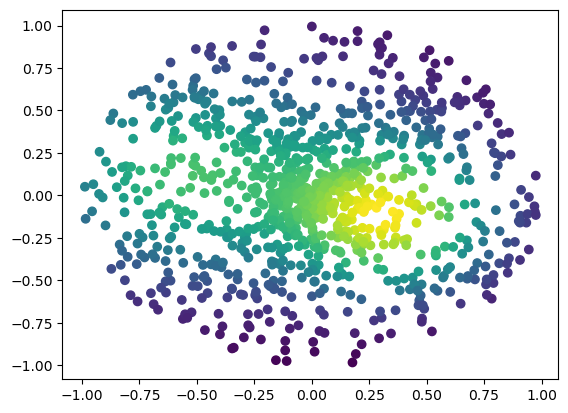

In [409]:
plt.scatter(x[:,0], x[:,1], c=y)

In [87]:
reglm = LinearRegression()
regt = DecisionTreeRegressor(random_state=0)
regsvr = SVR(C=1.0, epsilon=0.2)
regr = RandomForestRegressor(max_depth=2, random_state=0)
krr = KernelRidge(alpha=1.0)


bs = BSplines(x, df=[4]*2, degree=[3]*2)
alpha = np.array([10]*2)
df = pd.DataFrame({'x1':x[:,0], 'x2':x[:,1], 'y':y})
    
n = 30

lm_list = []
tree_list = []
svr_list = []
rr_list = []
krr_list = []
gam_list = []


for n in range(10,100):
    idx = np.random.choice(100, n, replace=False)
    reglm.fit(
        x[idx,:], 
        y[idx]
    )
    regt.fit(
        x[idx,:], 
        y[idx]
    )
    regsvr.fit(
        x[idx,:], 
        y[idx]
    )
    regr.fit(
        x[idx,:], 
        y[idx]
    )
    krr.fit(
        x[idx,:], 
        y[idx]
    )
    
    bs = BSplines(x[idx,:], df=[4]*2, degree=[3]*2)
    df = pd.DataFrame({'inter':1,'x1':x[idx,0], 'x2':x[idx,1], 'y':y[idx]})
    gam_bs = GLMGam.from_formula('y ~ inter', data=df,
                                     smoother=bs, alpha=alpha)
    res_gam = gam_bs.fit()


    #lm_list.append(reglm.score(x, y))
    #tree_list.append(regt.score(x, y))
    #svr_list.append(regsvr.score(x, y))
    #rr_list.append(regr.score(x, y))
    
    lm_list.append(np.power(reglm.predict(x) - y, 2).mean())
    tree_list.append(np.power(regt.predict(x) - y, 2).mean())
    svr_list.append(np.power(regsvr.predict(x) - y, 2).mean())
    rr_list.append(np.power(regr.predict(x) - y, 2).mean())
    krr_list.append(np.power(krr.predict(x) - y, 2).mean())
    a_min = max(df.min()[1],df.min()[2])
    a_max = min(df.max()[1],df.max()[2])
    df1 = pd.DataFrame({'inter':1,'x1':x[:,0], 'x2':x[:,1], 'y':y})
    
    gam_list.append(
        np.power(y - res_gam.predict(df1.iloc[:,0], np.clip(df1.iloc[:,1:], a_min=a_min, a_max=a_max)),2).mean()
    )

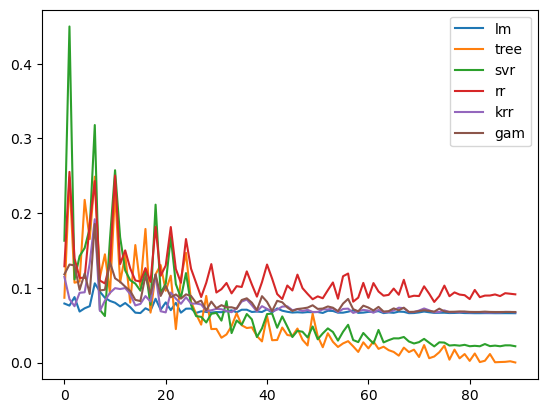

In [88]:
plt.plot(lm_list, label='lm')
plt.plot(tree_list, label='tree')
plt.plot(svr_list, label='svr')
plt.plot(rr_list, label='rr')
plt.plot(krr_list, label='krr')
plt.plot(gam_list, label='gam')

plt.legend()

In [64]:
x1, _ = gen_data()
y1 = np.random.normal(x1 @ theta, 0.1)

In [65]:
(reglm.score(x1, y1),
regt.score(x1, y1),
regsvr.score(x1, y1),
regr.score(x1, y1))

(0.9972046998012343, 0.595549996403625, 0.3499790470008979, 0.5720763978300503)

In [45]:
y1_ = regr.predict(x1)
y_ = regr.predict(x)

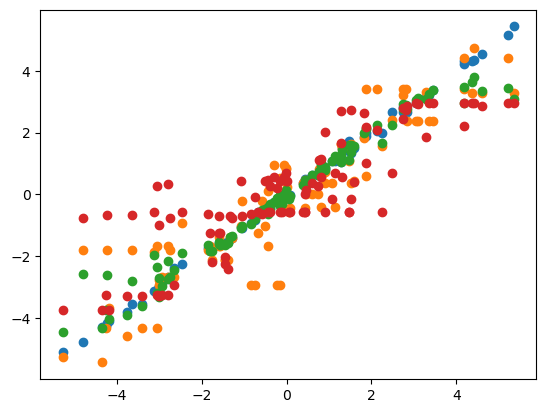

In [46]:
plt.scatter(y1, reglm.predict(x1))
plt.scatter(y1, regt.predict(x1))
plt.scatter(y1, regsvr.predict(x1))
plt.scatter(y1, regr.predict(x1))

In [47]:


#regsvr = make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2))


In [439]:
reglm = LinearRegression()
regt = DecisionTreeRegressor(random_state=0)
regsvr = SVR(C=1.0, epsilon=0.2)
regr = RandomForestRegressor(max_depth=2, random_state=0)

k=10

algos_dict = {
    'Greedy_T': [Greedy_f, {'reg_func':regt, 'k':k}, 100, 'Greedy_T', 'b'], 
    'TS_linear': [TS_linear, {}, 100, 'TS_linear', 'black'],  
    #'Greedy_linear': [Greedy_f, {}, 100, 'Greedy_linear', 'g'], 
    'Greedy_linear': [Greedy_f, {'reg_func':reglm, 'k':k}, 100, 'Greedy_linear', 'g'], 
    'Greedy_RR': [Greedy_f, {'reg_func':regr, 'k':k}, 100, 'Greedy_RR', 'r'], 
    'Greedy_SVM': [Greedy_f, {'reg_func':regsvr, 'k':k}, 100, 'Greedy_SVM', 'y'], 
    'Greedy_Frechet': [Greedy_Frechet, {'k':20, 'ss':6, 'dim':6, 'supp':None}, 10, 'Greedy_Frechet', 'm'],
    'Greedy_MLP': [Greedy_f, {'reg_func':model, 'k':k}, 100, 'Greedy_MLP', 'gray'], 
    
}

In [ ]:
M = 30
T = 100
reg_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
for trial_idx in trange(5):
    x, theta = gen_data(M, 5, 5)

    for algo, algo_setup in algos_dict.items():

        n_row, n_col = x.shape[0], 1
        _, n_desc =  x.shape
        cutoff = n_desc
        prob_dict = {
                    "m": n_row,
                    "noise": 0.01,
                    "d": cutoff,
                    "theta": theta,
                    "rwd_func":mean_
                    }
        prob = f_discover(**prob_dict)
        prob.x = x.copy()
            
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup

        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd = solver.run(T)[:2]

        reg_list[algo].append(reg)
        rwd_list[algo].append(np.cumsum(rwd))


 40%|██████████████████                           | 2/5 [02:04<03:07, 62.36s/it]

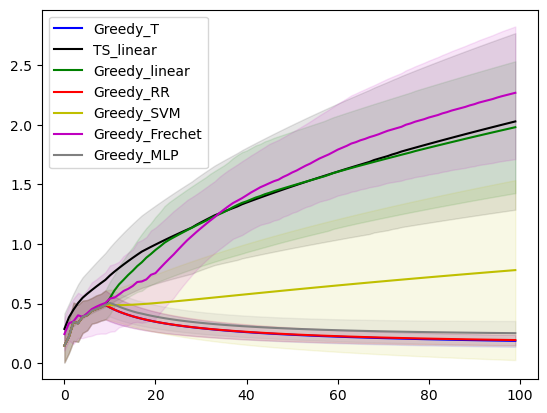

In [429]:
m = 0
n = 1000
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[m:n]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[m:n]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [111]:
solver.prob.rewards

[-1.415427540911059,
 -1.4167808759232672,
 -1.4056063614065035,
 -1.4000635712518776,
 -1.4078031790166516,
 -1.3956866151453966,
 -1.3865223374908264,
 -1.4002383456273066,
 -1.3949894773293678,
 -1.3886008425537528,
 -1.395176304615577,
 -1.3972264723626713,
 -1.3862863192386161,
 -1.3906116934092831,
 -1.4086976222603595,
 -1.396376858615698,
 -1.3969960845045355,
 -1.3780146261215334,
 -1.394555322758969,
 -1.3946749986027849,
 -1.3814214662356763,
 -1.4114938487980886,
 -1.3831618249506257,
 -1.4086273463276517,
 -1.398687993100846,
 -1.3909070826156444,
 -1.395495005418854,
 -1.377886837498762,
 -1.417467091367712,
 -1.4013017266207344,
 -1.3938292979608382,
 -1.406799638652663,
 -1.4081346275415239,
 -1.3961248386206677,
 -1.3941991286149151,
 -1.4045809268029796,
 -1.4017431097022952,
 -1.393120630188593,
 -1.4039379306182018,
 -1.4155007587590849,
 -1.410891430916281,
 -1.3807497720285749,
 -1.4107988830798175,
 -1.389672622123595,
 -1.3982004859117738,
 -1.4013538101699508,


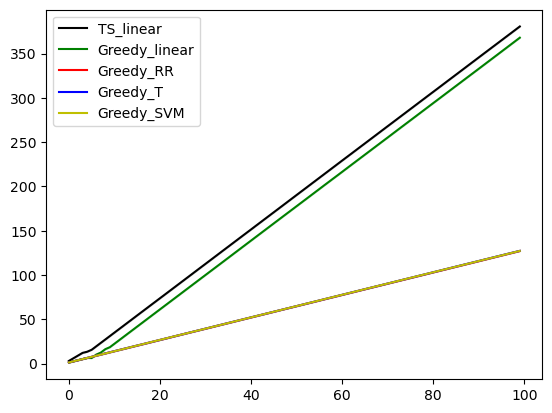

In [100]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(rwd_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(rwd_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [96]:
#p = np.random.rand(5)
p = np.ones(5) / 5

In [97]:
P = sklearn.metrics.pairwise_distances(x[:5])
P = ((1 - P / P.max(1)[:,None]) * p)
P = P / P.sum(1)[:,None]
P.sum(1)

array([1., 1., 1., 1., 1.])

In [102]:
Pn = P.copy()
for i in range(50):
    Pn = P @ Pn

In [120]:
np.concatenate([x[:5], x[:5].mean(0)[None,:]])

array([[-0.51387429, -0.4858232 ],
       [-0.09208713, -0.16469393],
       [ 0.05528665,  0.20329398],
       [-0.12640135,  0.8244633 ],
       [-0.72410064, -0.09601115],
       [-0.28023535,  0.0562458 ]])

In [136]:
np.sum(sklearn.metrics.pairwise_distances(np.concatenate([x[:5], x[:5].mean(0)[None,:]]))[5,:]/0.7834685880545222)

3.1903325669171547

In [145]:
(1-sklearn.metrics.pairwise_distances(np.concatenate([x[:5], x[:5].mean(0)[None,:]]))[5,:])/2.45

array([0.16723422, 0.28971564, 0.25864053, 0.08838017, 0.21663134,
       0.40816327])

In [104]:
Pn

array([[0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524]])

In [98]:
#pd.DataFrame((1 - P / P.max(1)))
pd.DataFrame(P)

,0,1,2,3,4
0,0.379683,0.232375,0.131326,0.000000,0.256616
1,0.191773,0.412956,0.247565,0.000000,0.147707
2,0.000000,0.293156,0.526800,0.145335,0.034710
3,0.000000,0.137904,0.263335,0.500311,0.098450
4,0.264330,0.186460,0.106045,0.000000,0.443165


In [87]:
P

array([[0.        , 0.53012113, 0.89377103, 1.36637696, 0.44288661],
       [0.53012113, 0.        , 0.39640148, 0.98975224, 0.63573454],
       [0.89377103, 0.39640148, 0.        , 0.64719537, 0.83488209],
       [1.36637696, 0.98975224, 0.64719537, 0.        , 1.0975052 ],
       [0.44288661, 0.63573454, 0.83488209, 1.0975052 , 0.        ]])

In [88]:
P / P.max(1)[:,None]

array([[0.        , 0.38797575, 0.65411747, 1.        , 0.32413208],
       [0.53560993, 0.        , 0.40050577, 1.        , 0.64231685],
       [1.        , 0.4435157 , 0.        , 0.72411764, 0.93411183],
       [1.        , 0.72436251, 0.47365799, 0.        , 0.80322285],
       [0.40353942, 0.57925424, 0.76070901, 1.        , 0.        ]])

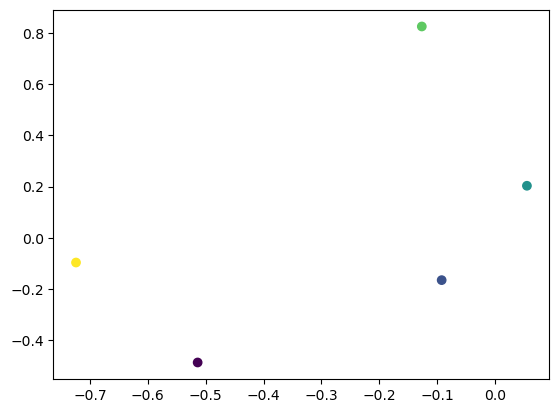

In [83]:
plt.scatter(x[:5,0], x[:5,1], c=range(5))

In [176]:
x.shape

torch.Size([1000, 2])

In [ ]:
plt.plot()

In [65]:
import torch
from torch import nn
import math
import time

In [438]:
class TwoLayerNet(torch.nn.Module):
    def __init__(self, D_in, H, D_out):
    
        """
        In the constructor we instantiate two nn.Linear modules and assign them as
        member variables.
        """
        super(TwoLayerNet, self).__init__()
        self.linear1 = torch.nn.Linear(D_in, H)
        self.linear2 = torch.nn.Linear(H, D_out)

    def forward(self, x):
        """
        In the forward function we accept a Tensor of input data and we must return
        a Tensor of output data. We can use Modules defined in the constructor as
        well as arbitrary (differentiable) operations on Tensors.
        """
        x_torch = torch.tensor(x).type(torch.FloatTensor)
        h_relu = self.linear1(x_torch).clamp(min=0)
        y_pred = self.linear2(h_relu)
        return y_pred
    
    def fit(self,
        x,
        y,
        num_epochs=1500,
        #batch_size,
        learning_rate=4e-4,
        lr_decay=1,
        device = torch.device("cpu"),
        print_loss=False
    ):
        loss_fn = torch.nn.MSELoss(reduction='sum')
        optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate)
        lr_scheduler = torch.optim.lr_scheduler.LambdaLR(
            optimizer, lambda epoch: lr_decay ** epoch
        )
        y_torch = torch.tensor(y).type(torch.FloatTensor)
        for t in range(num_epochs):
          # Forward pass: Compute predicted y by passing x to the model
            y_pred = self.forward(x)

          # Compute and print loss
            loss = loss_fn(y_pred.flatten(), y_torch)
            if print_loss:
                print(t, loss.item())

          # Zero gradients, perform a backward pass, and update the weights.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            #lr_scheduler.step()
        #print(loss.item())
        
    def predict(self, x):
        """
        In the forward function we accept a Tensor of input data and we must return
        a Tensor of output data. We can use Modules defined in the constructor as
        well as arbitrary (differentiable) operations on Tensors.
        """
        #x_torch = torch.tensor(x).type(torch.FloatTensor).clone().detach()
        with torch.no_grad():
            y_pred = self.forward(x)
        return y_pred.flatten()
        
loss_fn = torch.nn.MSELoss(reduction='sum')
# N is batch size; D_in is input dimension;
# H is hidden dimension; D_out is output dimension.
N, D_in = x.shape
H, D_out = 10, 1

# Create random Tensors to hold inputs and outputs
#x = torch.randn(N, D_in, device=device)
#theta = torch.randn(D_in, D_out, device=device)
#y = torch.pow(x @ theta, 1)

# Construct our model by instantiating the class defined above.
model = TwoLayerNet(D_in, H, D_out)


In [308]:
y = np.random.normal(np.power(x, 3)@ theta , 0.1)

In [314]:
model.fit(x=x, y=y)

In [315]:
((model.predict(x=x) - torch.tensor(y)) ** 2).sum()

tensor(0.1907, dtype=torch.float64)